
# Miniprojeto 1 — Análise Exploratória dos Dados (EDA)

**Disciplina:** Sistemas Inteligentes — CIn/UFPE

**Dataset:** `base_churn_5000_VF2_aluno.csv`

## Objetivo

Realizar uma análise exploratória da base de dados de clientes de uma operadora de telecomunicações, visando compreender sua estrutura, avaliar a qualidade das informações e identificar padrões relevantes para a previsão de cancelamento de contratos (*churn*).

A EDA contempla:

1. Inspeção inicial da base de dados.
2. Auditoria de qualidade e consistência.
3. Análise estatística descritiva.
4. Análise univariada das variáveis.
5. Análise bivariada e relações com o churn.
6. Análise de correlações e conclusões.

**Observação:** esta etapa tem caráter investigativo. Os tratamentos e transformações serão implementados posteriormente, na etapa de pré-processamento.



## 1. Importação das bibliotecas

Nesta etapa, importamos as bibliotecas necessárias para manipulação, análise e visualização dos dados.

- **pandas:** leitura e análise de dados tabulares.
- **numpy:** operações numéricas e estatísticas.
- **matplotlib:** construção de gráficos.
- **seaborn:** visualizações estatísticas.

Também configuramos a exibição das tabelas e o estilo dos gráficos para facilitar a interpretação dos resultados.


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid", palette="deep")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Bibliotecas importadas com sucesso!")


Bibliotecas importadas com sucesso!



# Parte 1 — Entendimento, Inspeção e Auditoria da Qualidade dos Dados

Nesta primeira etapa, realizamos a análise inicial da base de dados de clientes de uma operadora de telecomunicações, buscando compreender sua estrutura, identificar inconsistências e avaliar a qualidade das informações disponíveis.

A Parte 1 contempla:

1. **Entendimento do problema e carregamento:** contextualização do problema de churn, definição da data-base e leitura do dataset.
2. **Inventário dos atributos:** identificação das variáveis, seus tipos, características e funções na análise.
3. **Análise de completude:** identificação de valores ausentes e investigação dos padrões de ausência.
4. **Análise de unicidade:** identificação de registros duplicados e verificação da quantidade de clientes distintos.
5. **Análise de validade:** verificação dos domínios e das regras de negócio dos atributos categóricos, binários e numéricos.
6. **Análise de consistência temporal:** identificação de datas inválidas e eventos cronologicamente inconsistentes.
7. **Cobertura temporal e elegibilidade:** análise dos registros em relação à data-base e ao horizonte de previsão.
8. **Consolidação da qualidade:** síntese dos problemas identificados segundo as dimensões de completude, validade, consistência e unicidade.

Esta etapa possui caráter diagnóstico. **Nenhum tratamento será aplicado permanentemente à base original.**

Os resultados obtidos orientarão as próximas etapas da EDA e as decisões de pré-processamento, buscando garantir a qualidade, a consistência e a reprodutibilidade dos dados utilizados nos futuros experimentos de aprendizagem de máquina.


In [17]:
DATA_BASE = pd.Timestamp("2026-09-21")
FIM_JANELA = DATA_BASE + pd.Timedelta(days=60)

DATA_PATH = Path("../data/base_churn_5000_VF2_aluno.csv")

if not DATA_PATH.exists():
    DATA_PATH = Path("data/base_churn_5000_VF2_aluno.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {DATA_PATH}")

df = pd.read_csv(DATA_PATH, sep=None, engine="python")

print(f"Registros: {df.shape[0]}")
print(f"Atributos: {df.shape[1]}")
print("\nPrimeiros registros:")
display(df.head(5))


Registros: 5020
Atributos: 10

Primeiros registros:


,id_cliente,data_aquisicao_cliente,mensalidade_rs,data_chamado,atrasos_6m,tipo_contrato,forma_pagamento,fibra_optica,debito_automatico,data_ocorrencia_churn
0,C0001,21/04/2024,"67,96","09/09/2026, 15/08/2026",0.0,Bienal,Boleto,0,0,NaN
1,C0002,21/02/2025,"65,95",NaN,0.0,Mensal,Cartão,0,0,NaN
2,C0003,21/03/2025,"100,88",28/08/2026,1.0,Anual,Boleto,1,1,NaN
3,C0004,21/03/2025,"94,8","06/08/2026, 28/07/2026",2.0,Mensal,Cartão,0,1,NaN
4,C0005,21/02/2022,"53,68",05/07/2026,2.0,Anual,Pix,0,0,NaN



## 3. Inventário e classificação dos atributos

O inventário de atributos permite compreender o significado, o tipo e a função de cada variável na análise.

A base contém informações de diferentes naturezas:

- **Identificação:** código único do cliente.
- **Temporais:** datas de aquisição, chamados e cancelamento.
- **Numéricas:** mensalidade e quantidade de atrasos.
- **Categóricas:** tipo de contrato e forma de pagamento.
- **Binárias:** presença de fibra óptica e débito automático.

Algumas variáveis serão utilizadas diretamente como preditoras, enquanto outras serão transformadas em atributos derivados.

A coluna `data_ocorrencia_churn` será utilizada para construir o alvo, mas não deverá ser utilizada diretamente como variável preditora, pois contém informação sobre um evento futuro.

Nesta etapa, investigamos os tipos de dados identificados pelo pandas, a quantidade de valores disponíveis e a cardinalidade das variáveis.


In [16]:

inventario = pd.DataFrame({
    "Tipo identificado": df.dtypes.astype(str),
    "Não nulos": df.notna().sum(),
    "Nulos": df.isna().sum(),
    "Valores distintos": df.nunique(dropna=True)
})

display(inventario)

print("\nInformações gerais:")
df.info()


,Tipo identificado,Não nulos,Nulos,Valores distintos
id_cliente,str,5020,0,5000
data_aquisicao_cliente,str,5020,0,86
mensalidade_rs,str,4900,120,3339
data_chamado,str,3967,1053,2407
atrasos_6m,float64,4985,35,7
tipo_contrato,str,4994,26,6
forma_pagamento,str,5000,20,6
fibra_optica,int64,5020,0,2
debito_automatico,int64,5020,0,2
data_ocorrencia_churn,str,1789,3231,61



Informações gerais:
<class 'pandas.DataFrame'>
RangeIndex: 5020 entries, 0 to 5019
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_cliente              5020 non-null   str    
 1   data_aquisicao_cliente  5020 non-null   str    
 2   mensalidade_rs          4900 non-null   str    
 3   data_chamado            3967 non-null   str    
 4   atrasos_6m              4985 non-null   float64
 5   tipo_contrato           4994 non-null   str    
 6   forma_pagamento         5000 non-null   str    
 7   fibra_optica            5020 non-null   int64  
 8   debito_automatico       5020 non-null   int64  
 9   data_ocorrencia_churn   1789 non-null   str    
dtypes: float64(1), int64(2), str(7)
memory usage: 392.3 KB



## 4. Completude dos dados

A completude mede a presença das informações necessárias para a análise.

Nesta etapa, investigamos a quantidade e o percentual de valores ausentes em cada atributo, além da proporção de registros com pelo menos um campo vazio.

Entretanto, nem toda ausência representa um problema de qualidade:

- `data_ocorrencia_churn` vazia pode indicar ausência de cancelamento registrado.
- `data_chamado` vazia pode indicar ausência de chamados.
- `mensalidade_rs` vazia representa uma informação financeira não disponível.
- Ausências em contrato, pagamento e atrasos exigem investigação e possível imputação.

A Aula 2 apresenta três mecanismos de ausência:

- **MCAR:** ausência completamente aleatória.
- **MAR:** ausência explicável por outras variáveis observadas.
- **MNAR:** ausência relacionada ao próprio valor não observado.

A simples contagem de valores ausentes não permite determinar qual mecanismo ocorreu. Essa classificação exige investigação adicional.

Nenhuma imputação será realizada nesta etapa.


,Quantidade,Percentual (%)
data_ocorrencia_churn,3231,64.36
data_chamado,1053,20.98
mensalidade_rs,120,2.39
atrasos_6m,35,0.70
tipo_contrato,26,0.52
forma_pagamento,20,0.40
data_aquisicao_cliente,0,0.00
id_cliente,0,0.00
fibra_optica,0,0.00
debito_automatico,0,0.00


Registros com pelo menos um campo ausente: 3525
Percentual de registros: 70.22%


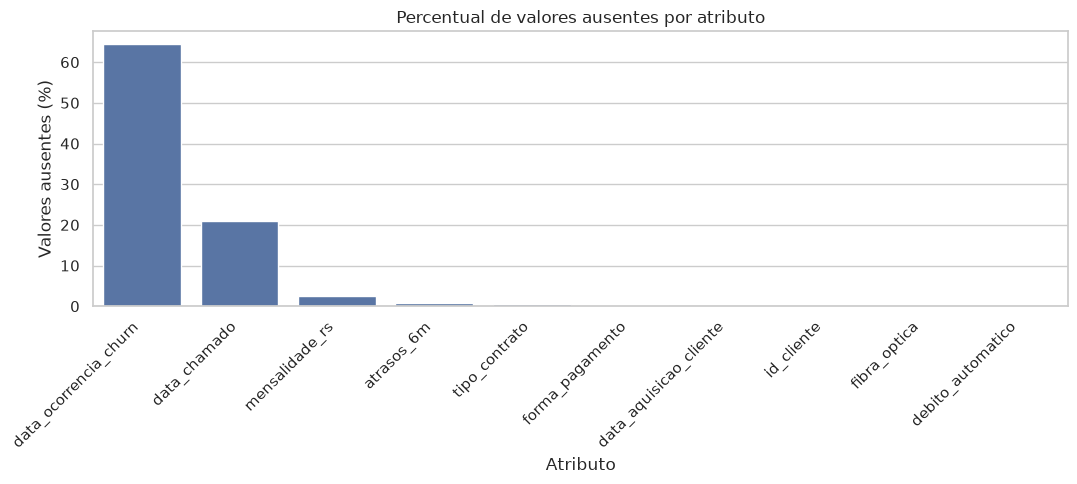

In [18]:

nulos = pd.DataFrame({
    "Quantidade": df.isna().sum(),
    "Percentual (%)": (df.isna().mean() * 100).round(2)
}).sort_values("Percentual (%)", ascending=False)

display(nulos)

linhas_com_nulos = df.isna().any(axis=1).sum()

print(f"Registros com pelo menos um campo ausente: {linhas_com_nulos}")
print(f"Percentual de registros: {linhas_com_nulos / len(df) * 100:.2f}%")

plt.figure(figsize=(11, 5))

sns.barplot(
    x=nulos.index,
    y=nulos["Percentual (%)"]
)

plt.title("Percentual de valores ausentes por atributo")
plt.xlabel("Atributo")
plt.ylabel("Valores ausentes (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()



### 4.1. Padrões de ausência

Além da quantidade de valores ausentes por atributo, investigamos a ocorrência simultânea de ausências em campos que representam características efetivas dos clientes.

Para essa análise, consideramos mensalidade, atrasos, tipo de contrato e forma de pagamento.

As datas de chamados e cancelamento são excluídas dessa contagem específica porque sua ausência pode representar um evento que não ocorreu, e não necessariamente uma falha de registro.


In [19]:

colunas_completude = [
    "mensalidade_rs",
    "atrasos_6m",
    "tipo_contrato",
    "forma_pagamento"
]

quantidade_ausencias = df[colunas_completude].isna().sum(axis=1)

resumo_ausencias = (
    quantidade_ausencias.value_counts()
    .sort_index()
    .rename_axis("Campos ausentes por registro")
    .reset_index(name="Quantidade de registros")
)

resumo_ausencias["Percentual (%)"] = (
    resumo_ausencias["Quantidade de registros"]
    / len(df) * 100
).round(2)

display(resumo_ausencias)


,Campos ausentes por registro,Quantidade de registros,Percentual (%)
0,0,4821,96.04
1,1,197,3.92
2,2,2,0.04



## 5. Unicidade e duplicação de registros

A unicidade verifica se os registros representam corretamente as unidades de análise, sem repetições indevidas.

A granularidade prevista é de um registro por cliente na data-base. Portanto, é necessário verificar:

- Linhas completamente duplicadas.
- Identificadores de clientes repetidos.
- Quantidade de clientes distintos.
- Diferenças entre registros que possuem o mesmo identificador.

A presença de duplicatas pode distorcer estatísticas e causar vazamento de informações se registros idênticos forem distribuídos entre treino e teste.

Nesta etapa, apenas identificamos e documentamos as ocorrências. A resolução será feita no pré-processamento.


In [20]:

duplicatas_completas = df.duplicated().sum()

ids_repetidos = df.duplicated(
    subset=["id_cliente"]
).sum()

clientes_unicos = df["id_cliente"].nunique()

print(f"Total de registros: {len(df)}")
print(f"Clientes distintos: {clientes_unicos}")
print(f"Linhas totalmente duplicadas: {duplicatas_completas}")
print(f"Ocorrências adicionais de IDs repetidos: {ids_repetidos}")

ids_exemplos = (
    df.loc[df.duplicated(subset=["id_cliente"], keep=False), "id_cliente"]
    .drop_duplicates()
    .head(3)
)

display(
    df[df["id_cliente"].isin(ids_exemplos)]
    .sort_values("id_cliente")
)


Total de registros: 5020
Clientes distintos: 5000
Linhas totalmente duplicadas: 20
Ocorrências adicionais de IDs repetidos: 20


,id_cliente,data_aquisicao_cliente,mensalidade_rs,data_chamado,atrasos_6m,tipo_contrato,forma_pagamento,fibra_optica,debito_automatico,data_ocorrencia_churn
496,C0497,21/07/2024,"110,68",02/08/2026,2.0,Mensal,Cartão,1,0,04/10/2026
5004,C0497,21/07/2024,"110,68",02/08/2026,2.0,Mensal,Cartão,1,0,04/10/2026
806,C0807,21/12/2025,"77,4","09/09/2026, 05/09/2026, 30/06/2026",2.0,Anual,Cartão,0,0,NaN
5003,C0807,21/12/2025,"77,4","09/09/2026, 05/09/2026, 30/06/2026",2.0,Anual,Cartão,0,0,NaN
856,C0857,21/01/2025,"104,26",19/08/2026,2.0,Bienal,Boleto,1,0,NaN
5013,C0857,21/01/2025,"104,26",19/08/2026,2.0,Bienal,Boleto,1,0,NaN



## 6. Validade dos atributos categóricos e binários

A validade verifica se os valores armazenados respeitam os domínios estabelecidos no dicionário de dados.

Os atributos categóricos possuem os seguintes valores canônicos:

| Atributo | Domínio esperado |
|---|---|
| `tipo_contrato` | Mensal, Anual, Bienal |
| `forma_pagamento` | Boleto, Cartão, Pix |
| `fibra_optica` | 0, 1 |
| `debito_automatico` | 0, 1 |

Serão investigadas as frequências absolutas e relativas de cada categoria, incluindo valores ausentes.

Também verificaremos inconsistências de padronização, como diferenças entre letras maiúsculas e minúsculas, acentuação e espaços extras.

É importante diferenciar categorias desconhecidas de categorias válidas escritas de maneira não canônica. Esta distinção orientará as regras de padronização durante o pré-processamento.


In [21]:

colunas_categoricas = [
    "tipo_contrato",
    "forma_pagamento",
    "fibra_optica",
    "debito_automatico"
]

for coluna in colunas_categoricas:
    print(f"\nATRIBUTO: {coluna}")

    tabela = pd.DataFrame({
        "Frequência": df[coluna].value_counts(dropna=False),
        "Percentual (%)": (
            df[coluna].value_counts(
                normalize=True, dropna=False
            ) * 100
        ).round(2)
    })

    display(tabela)



ATRIBUTO: tipo_contrato


,Frequência,Percentual (%)
tipo_contrato,,
Mensal,2726,54.30
Anual,1184,23.59
Bienal,1004,20.00
mensal,40,0.80
NaN,26,0.52
anual,25,0.50
bienal,15,0.30



ATRIBUTO: forma_pagamento


,Frequência,Percentual (%)
forma_pagamento,,
Boleto,1953,38.90
Cartão,1696,33.78
Pix,1261,25.12
cartao,50,1.00
boleto,25,0.50
NaN,20,0.40
PIX,15,0.30



ATRIBUTO: fibra_optica


,Frequência,Percentual (%)
fibra_optica,,
1,2852,56.81
0,2168,43.19



ATRIBUTO: debito_automatico


,Frequência,Percentual (%)
debito_automatico,,
0,3031,60.38
1,1989,39.62



### 6.1. Verificação dos domínios categóricos

Nesta etapa, contabilizamos registros cujos valores não pertencem aos domínios canônicos definidos no dicionário.

Os valores ausentes são contabilizados separadamente, pois representam um problema de completude, não uma categoria não canônica.

Essa distinção permite diferenciar:

- Valores válidos.
- Valores presentes, mas fora do domínio esperado.
- Valores ausentes.

Os resultados serão utilizados posteriormente para definir regras de padronização e validação da base.


In [23]:

dominios = {
    "tipo_contrato": ["Mensal", "Anual", "Bienal"],
    "forma_pagamento": ["Boleto", "Cartão", "Pix"],
    "fibra_optica": [0, 1],
    "debito_automatico": [0, 1]
}

resultados_categoricos = []

for coluna, valores_validos in dominios.items():
    invalidos = (
        df[coluna].notna()
        & ~df[coluna].isin(valores_validos)
    )

    resultados_categoricos.append({
        "Atributo": coluna,
        "Ausentes": int(df[coluna].isna().sum()),
        "Não canônicos": int(invalidos.sum()),
        "Percentual não canônico (%)": round(
            invalidos.mean() * 100, 2
        )
    })

display(pd.DataFrame(resultados_categoricos))


,Atributo,Ausentes,Não canônicos,Percentual não canônico (%)
0,tipo_contrato,26,80,1.59
1,forma_pagamento,20,90,1.79
2,fibra_optica,0,0,0.00
3,debito_automatico,0,0,0.00



## 7. Auditoria dos atributos numéricos

A análise de validade numérica verifica se os atributos apresentam valores compatíveis com seus tipos e limites de negócio.

De acordo com a Aula 2, os domínios esperados são:

| Atributo | Domínio válido |
|---|---|
| `mensalidade_rs` | R$ 10 a R$ 500 |
| `atrasos_6m` | Inteiros de 0 a 6 |

Serão verificadas:

1. Quantidade de valores ausentes.
2. Valores que não podem ser convertidos para números.
3. Valores inferiores ou superiores aos limites permitidos.
4. Valores não inteiros em variáveis que representam contagens.

A mensalidade utiliza vírgula como separador decimal. Para evitar erros de interpretação, faremos uma conversão temporária para o formato numérico do Python.

Valores fora do domínio não serão automaticamente considerados outliers estatísticos válidos, pois podem representar erros de registro. A decisão de tratamento será feita posteriormente.


In [24]:

regras_numericas = {
    "mensalidade_rs": (10, 500),
    "atrasos_6m": (0, 6)
}

resultados_numericos = []

# Conversão temporária, sem modificar o DataFrame original.
mensalidade_num = pd.to_numeric(
    df["mensalidade_rs"]
    .astype("string")
    .str.strip()
    .str.replace(",", ".", regex=False),
    errors="coerce"
)

atrasos_num = pd.to_numeric(
    df["atrasos_6m"],
    errors="coerce"
)

numericos_convertidos = {
    "mensalidade_rs": mensalidade_num,
    "atrasos_6m": atrasos_num
}

for coluna, (minimo, maximo) in regras_numericas.items():
    originais = df[coluna]
    valores = numericos_convertidos[coluna]

    falhas_conversao = originais.notna() & valores.isna()
    fora_faixa = valores.notna() & ~valores.between(minimo, maximo)

    nao_inteiros = (
        valores.notna() & (valores % 1 != 0)
        if coluna == "atrasos_6m"
        else pd.Series(False, index=df.index)
    )

    invalidos = falhas_conversao | fora_faixa | nao_inteiros

    resultados_numericos.append({
        "Atributo": coluna,
        "Ausentes": int(originais.isna().sum()),
        "Falhas de conversão": int(falhas_conversao.sum()),
        "Fora da faixa": int(fora_faixa.sum()),
        "Não inteiros": int(nao_inteiros.sum()),
        "Total inválidos": int(invalidos.sum())
    })

    if invalidos.any():
        print(f"\nExemplos de registros inválidos: {coluna}")
        display(
            df.loc[invalidos, ["id_cliente", coluna]].head(5)
        )

print("\nRESUMO DA AUDITORIA NUMÉRICA")
display(pd.DataFrame(resultados_numericos))



Exemplos de registros inválidos: mensalidade_rs


,id_cliente,mensalidade_rs
279,C0280,-85
332,C0333,9999
507,C0508,-85
1199,C1200,9999
1865,C1866,9999



Exemplos de registros inválidos: atrasos_6m


,id_cliente,atrasos_6m
115,C0116,99.0
876,C0877,99.0
976,C0977,99.0
2684,C2685,99.0
3268,C3269,99.0



RESUMO DA AUDITORIA NUMÉRICA


,Atributo,Ausentes,Falhas de conversão,Fora da faixa,Não inteiros,Total inválidos
0,mensalidade_rs,120,0,12,0,12
1,atrasos_6m,35,0,8,0,8



## 8. Consistência temporal dos registros

A análise de consistência verifica se existe coerência lógica entre as datas registradas.

As principais regras investigadas são:

- A data de aquisição deve ser válida e não pode ocorrer após a data-base, para clientes elegíveis na fotografia inicial.
- Um cancelamento não pode ocorrer antes da aquisição do cliente.
- Um chamado de suporte não pode ocorrer antes da aquisição do cliente.
- Os chamados utilizados como informações preditoras precisam estar disponíveis até a data-base.
- As datas de cancelamento utilizadas para construir o alvo devem respeitar o horizonte de previsão.

Também verificamos se existem datas com formatos diferentes ou impossíveis de interpretar.

Essas verificações são fundamentais para prevenir inconsistências e vazamento temporal de informações (*data leakage*).

Nesta etapa, as datas são convertidas apenas em estruturas auxiliares para a auditoria, sem modificar as colunas originais.


In [25]:

def converter_data(valor):
    if pd.isna(valor) or not str(valor).strip():
        return pd.NaT

    valor = str(valor).strip()

    # Formato ISO: AAAA-MM-DD
    if len(valor) >= 10 and valor[4] == "-":
        return pd.to_datetime(
            valor, format="%Y-%m-%d", errors="coerce"
        )

    # Formato brasileiro: DD/MM/AAAA
    return pd.to_datetime(
        valor, format="%d/%m/%Y", errors="coerce"
    )


aquisicao = df["data_aquisicao_cliente"].apply(converter_data)
churn_data = df["data_ocorrencia_churn"].apply(converter_data)


def converter_chamados(valor):
    if pd.isna(valor) or not str(valor).strip():
        return []

    return [
        converter_data(parte.strip())
        for parte in str(valor).split(",")
    ]


chamados = df["data_chamado"].apply(converter_chamados)

aquisicao_invalida = (
    df["data_aquisicao_cliente"].notna()
    & aquisicao.isna()
)

churn_invalido = (
    df["data_ocorrencia_churn"].notna()
    & churn_data.isna()
)

datas_chamados_invalidas = chamados.apply(
    lambda datas: sum(pd.isna(d) for d in datas)
).sum()

churn_antes_aquisicao = (
    churn_data.notna()
    & aquisicao.notna()
    & (churn_data < aquisicao)
)

chamados_antes_aquisicao = pd.Series(
    {
        idx: (
            pd.notna(aquisicao.loc[idx])
            and any(
                pd.notna(d) and d < aquisicao.loc[idx]
                for d in datas
            )
        )
        for idx, datas in chamados.items()
    }
)

chamados_apos_corte = chamados.apply(
    lambda datas: any(
        pd.notna(d) and d > DATA_BASE
        for d in datas
    )
)

resumo_consistencia = pd.DataFrame({
    "Verificação": [
        "Datas de aquisição inválidas",
        "Datas de churn inválidas",
        "Datas individuais de chamados inválidas",
        "Churn anterior à aquisição",
        "Registros com chamados antes da aquisição",
        "Registros com chamados após a data-base"
    ],
    "Quantidade": [
        int(aquisicao_invalida.sum()),
        int(churn_invalido.sum()),
        int(datas_chamados_invalidas),
        int(churn_antes_aquisicao.sum()),
        int(chamados_antes_aquisicao.sum()),
        int(chamados_apos_corte.sum())
    ]
})

display(resumo_consistencia)

problemas_temporais = (
    aquisicao_invalida
    | churn_invalido
    | churn_antes_aquisicao
    | chamados_antes_aquisicao
    | chamados_apos_corte
)

print("\nExemplos de registros com problemas temporais:")
display(
    df.loc[
        problemas_temporais,
        [
            "id_cliente",
            "data_aquisicao_cliente",
            "data_chamado",
            "data_ocorrencia_churn"
        ]
    ].head(5)
)


,Verificação,Quantidade
0,Datas de aquisição inválidas,0
1,Datas de churn inválidas,0
2,Datas individuais de chamados inválidas,0
3,Churn anterior à aquisição,10
4,Registros com chamados antes da aquisição,33
5,Registros com chamados após a data-base,0



Exemplos de registros com problemas temporais:


,id_cliente,data_aquisicao_cliente,data_chamado,data_ocorrencia_churn
202,C0203,21/08/2024,"16/09/2026, 13/09/2026, 03/09/2026",15/01/2020
383,C0384,21/04/2025,05/01/2019,28/09/2026
494,C0495,21/08/2025,"27/08/2026, 06/07/2026",15/01/2020
802,C0803,21/03/2022,05/01/2019,NaN
1152,C1153,21/07/2026,"23/08/2026, 24/07/2026, 11/07/2026",18/10/2026



### 8.1. Formatos utilizados nas datas

Além da validade cronológica, é necessário verificar a padronização dos formatos.

A presença de datas em diferentes padrões pode causar falhas de conversão, ordenação e construção de atributos temporais.

O objetivo é contabilizar os formatos utilizados nas colunas de aquisição e churn, distinguindo valores brasileiros, valores ISO, ausências e outros formatos.


In [26]:

def identificar_formato(valor):
    if pd.isna(valor):
        return "Ausente"

    valor = str(valor).strip()

    if pd.isna(pd.to_datetime(valor, format="%d/%m/%Y", errors="coerce")) is False:
        return "DD/MM/AAAA"

    if pd.isna(pd.to_datetime(valor, format="%Y-%m-%d", errors="coerce")) is False:
        return "AAAA-MM-DD"

    return "Outro / inválido"


for coluna in [
    "data_aquisicao_cliente",
    "data_ocorrencia_churn"
]:
    print(f"\nFormato das datas: {coluna}")

    display(
        df[coluna].apply(identificar_formato)
        .value_counts(dropna=False)
        .to_frame("Quantidade")
    )



Formato das datas: data_aquisicao_cliente


,Quantidade
data_aquisicao_cliente,
DD/MM/AAAA,5005
AAAA-MM-DD,15



Formato das datas: data_ocorrencia_churn


,Quantidade
data_ocorrencia_churn,
Ausente,3231
DD/MM/AAAA,1789



## 9. Cobertura temporal e elegibilidade dos clientes

A previsão de churn depende da definição correta de uma população de clientes ativos em uma data de referência.

Para este projeto, consideramos:

- **Data-base:** 21/09/2026.
- **Horizonte de previsão:** 60 dias.
- **Janela de churn:** de 22/09/2026 até 20/11/2026, inclusive.

Nesta etapa, investigamos:

1. O período de aquisição dos clientes.
2. A quantidade de clientes adquiridos após a data-base.
3. Cancelamentos anteriores à data-base.
4. Cancelamentos na janela futura de 60 dias.
5. Cancelamentos posteriores ao horizonte definido.
6. Registros sem data de cancelamento.

Um cliente que já havia cancelado antes da data-base não deve ser automaticamente considerado um cliente que permaneceu durante a janela futura.

Além disso, as contagens ainda representam linhas da base original e podem incluir duplicatas ou registros inconsistentes. A definição definitiva da população elegível será realizada na etapa de construção da base analítica.


In [28]:

resumo_cobertura = pd.DataFrame({
    "Indicador": [
        "Primeira data de aquisição",
        "Última data de aquisição",
        "Aquisições posteriores à data-base",
        "Cancelamentos anteriores à data-base",
        "Cancelamentos exatamente na data-base",
        "Cancelamentos na janela de 60 dias",
        "Cancelamentos após os 60 dias",
        "Registros sem data de cancelamento"
    ],
    "Resultado": [
        aquisicao.min(),
        aquisicao.max(),
        int((aquisicao > DATA_BASE).sum()),
        int((churn_data < DATA_BASE).sum()),
        int((churn_data == DATA_BASE).sum()),
        int((
            (churn_data > DATA_BASE)
            & (churn_data <= FIM_JANELA)
        ).sum()),
        int((churn_data > FIM_JANELA).sum()),
        int(churn_data.isna().sum())
    ]
})

display(resumo_cobertura)


,Indicador,Resultado
0,Primeira data de aquisição,2020-09-21 00:00:00
1,Última data de aquisição,2026-08-21 00:00:00
2,Aquisições posteriores à data-base,0
3,Cancelamentos anteriores à data-base,10
4,Cancelamentos exatamente na data-base,0
5,Cancelamentos na janela de 60 dias,1779
6,Cancelamentos após os 60 dias,0
7,Registros sem data de cancelamento,3231



### 9.1. Distribuição preliminar do alvo

O objetivo é estimar a distribuição inicial das classes de churn, considerando apenas registros temporalmente elegíveis.

Esta é uma verificação preliminar para avaliar o possível desbalanceamento das classes, e não a construção definitiva da variável-alvo.

Para evitar distorções, utilizamos uma cópia sem duplicatas completas e excluímos registros com aquisição posterior à data-base, cancelamento até a data-base ou inconsistências temporais conhecidas envolvendo a aquisição.

As demais regras de elegibilidade e qualidade serão consolidadas no pré-processamento.


In [29]:

# Seleção apenas para diagnóstico.
mask_elegivel = (
    aquisicao.notna()
    & (aquisicao <= DATA_BASE)
    & (
        churn_data.isna()
        | (churn_data > DATA_BASE)
    )
    & ~churn_antes_aquisicao
)

df_preliminar = df.loc[mask_elegivel].drop_duplicates().copy()

datas_churn_preliminar = churn_data.loc[df_preliminar.index]

churn_preliminar = (
    (datas_churn_preliminar > DATA_BASE)
    & (datas_churn_preliminar <= FIM_JANELA)
).astype(int)

distribuicao_preliminar = pd.DataFrame({
    "Quantidade": churn_preliminar.value_counts().sort_index(),
    "Percentual (%)": (
        churn_preliminar.value_counts(
            normalize=True
        ).sort_index() * 100
    ).round(2)
})

distribuicao_preliminar.index = distribuicao_preliminar.index.map({
    0: "Sem churn na janela",
    1: "Com churn na janela"
})

print(f"Registros preliminarmente elegíveis: {len(df_preliminar)}")
display(distribuicao_preliminar)


Registros preliminarmente elegíveis: 4990


,Quantidade,Percentual (%)
data_ocorrencia_churn,,
Sem churn na janela,3218,64.49
Com churn na janela,1772,35.51



## 10. Consolidação da auditoria da qualidade

A auditoria foi organizada em quatro dimensões fundamentais:

- **Completude:** presença das informações necessárias.
- **Validade:** conformidade com tipos, faixas e domínios esperados.
- **Consistência:** coerência lógica e temporal entre os atributos.
- **Unicidade:** inexistência de duplicatas indevidas.

O quadro a seguir sintetiza os principais problemas identificados e facilita a definição das prioridades de pré-processamento.

Os indicadores representam contagens de diferentes problemas e não devem ser somados diretamente, pois um mesmo registro pode apresentar múltiplas violações.


In [31]:

total_invalidos_numericos = sum(
    item["Total inválidos"]
    for item in resultados_numericos
)

total_nao_canonicos = sum(
    item["Não canônicos"]
    for item in resultados_categoricos
)

resumo_qualidade = pd.DataFrame({
    "Dimensão": [
        "Completude",
        "Completude",
        "Validade",
        "Validade",
        "Consistência",
        "Consistência",
        "Unicidade"
    ],
    "Indicador": [
        "Registros com ausência em campos de perfil",
        "Registros com alguma ausência na base",
        "Ocorrências de valores numéricos inválidos",
        "Ocorrências de categorias não canônicas",
        "Cancelamentos anteriores à aquisição",
        "Registros com chamados anteriores à aquisição",
        "Linhas duplicadas completas"
    ],
    "Quantidade": [
        int(df[colunas_completude].isna().any(axis=1).sum()),
        int(df.isna().any(axis=1).sum()),
        int(total_invalidos_numericos),
        int(total_nao_canonicos),
        int(churn_antes_aquisicao.sum()),
        int(len(chamados_antes_aquisicao)),
        int(duplicatas_completas)
    ]
})

display(resumo_qualidade)


,Dimensão,Indicador,Quantidade
0,Completude,Registros com ausência em campos de perfil,199
1,Completude,Registros com alguma ausência na base,3525
2,Validade,Ocorrências de valores numéricos inválidos,20
3,Validade,Ocorrências de categorias não canônicas,170
4,Consistência,Cancelamentos anteriores à aquisição,10
5,Consistência,Registros com chamados anteriores à aquisição,33
6,Unicidade,Linhas duplicadas completas,20



## 11. Conclusões da inspeção e auditoria inicial

A Parte 1 teve como objetivo compreender a estrutura do dataset e identificar problemas relacionados às dimensões de qualidade dos dados.

### Estrutura e granularidade

A base contém registros de clientes de uma operadora de telecomunicações, incluindo informações financeiras, contratuais, comportamentais e temporais.

A unidade analítica desejada é um cliente observado em uma data-base, para previsão de churn nos 60 dias subsequentes.

### Completude

Foram investigadas as ausências por atributo e os padrões de campos não preenchidos simultaneamente.

É necessário diferenciar ausências informativas, como a inexistência de chamados ou cancelamento, de ausências em atributos necessários para a análise.

### Validade

Foram verificadas as regras de domínio dos atributos numéricos, categóricos e binários.

As inconsistências encontradas deverão orientar a padronização dos dados, o tratamento de valores inválidos e a definição de estratégias de imputação.

### Consistência

A auditoria temporal investigou a coerência entre datas de aquisição, chamados de suporte e cancelamentos.

Registros com eventos anteriores à aquisição ou incompatíveis com a data-base exigem decisões específicas de tratamento.

### Unicidade

A verificação de duplicatas permite identificar repetições indevidas que poderiam distorcer análises e comprometer a avaliação dos modelos.

### Encaminhamento

Os resultados obtidos nesta etapa serão utilizados para planejar a construção da visão analítica, o pré-processamento e a análise exploratória estatística.

Antes da EDA orientada à modelagem, será necessário consolidar a definição dos registros elegíveis e isolar o conjunto de teste, de acordo com o protocolo de prevenção de data leakage apresentado na Aula 3.



# Parte 2 — Estatística Descritiva e Análise Univariada

Nesta etapa, investigamos as características individuais dos atributos da base de dados, utilizando medidas estatísticas e visualizações para compreender suas distribuições.

A Parte 2 contempla:

1. **Preparação da visão analítica:** definição dos registros elegíveis, construção da variável-alvo e divisão entre treino e teste.
2. **Estatística descritiva:** análise de média, mediana, desvio-padrão, quartis e valores extremos.
3. **Distribuição das variáveis numéricas:** investigação da mensalidade e da quantidade de atrasos.
4. **Tempo de relacionamento:** análise da duração do vínculo dos clientes com a operadora.
5. **Chamados de suporte:** análise da quantidade de chamados registrados nos últimos 90 dias.
6. **Identificação de outliers:** investigação de possíveis valores extremos.
7. **Distribuição dos atributos categóricos e binários:** análise das frequências de contratos, formas de pagamento, fibra óptica e débito automático.

As análises estatísticas serão realizadas exclusivamente sobre o conjunto de treinamento, mantendo o conjunto de teste isolado para evitar vazamento de informações (*data leakage*).

O objetivo é compreender o comportamento individual dos atributos e identificar características relevantes para a preparação da base e para as análises de associação com o churn realizadas na Parte 3.



## 12. Preparação da visão analítica e divisão treino/teste

Antes de realizar as análises estatísticas, construímos uma visão analítica provisória com um registro por cliente, preservando a base original.

Nesta etapa:

- Removemos duplicatas completas.
- Consideramos clientes adquiridos até a data-base e sem cancelamento anterior ou na própria data-base.
- Construímos a variável-alvo `churn` a partir da janela futura de 60 dias.
- Separamos 70% dos registros para treino e 30% para teste, utilizando estratificação e `random_state=42`.

As transformações realizadas nesta etapa são determinísticas. Nenhuma imputação ou transformação estatística é ajustada utilizando o conjunto de teste.

As análises seguintes utilizarão exclusivamente os dados de treinamento.


In [32]:

from sklearn.model_selection import train_test_split

# Visão analítica provisória: um registro por cliente elegível
df_analitico = df.loc[
    aquisicao.notna()
    & (aquisicao <= DATA_BASE)
    & (churn_data.isna() | (churn_data > DATA_BASE))
].drop_duplicates().copy()

# Construção do alvo
datas_churn = churn_data.loc[df_analitico.index]

df_analitico["churn"] = (
    (datas_churn > DATA_BASE)
    & (datas_churn <= FIM_JANELA)
).astype(int)

# Divisão estratificada, antes da análise estatística
df_treino, df_teste = train_test_split(
    df_analitico,
    test_size=0.30,
    random_state=42,
    stratify=df_analitico["churn"]
)

print(f"Base analítica: {len(df_analitico)} registros")
print(f"Treino: {len(df_treino)} registros")
print(f"Teste reservado: {len(df_teste)} registros")


Base analítica: 4990 registros
Treino: 3493 registros
Teste reservado: 1497 registros



## 13. Estatística descritiva das variáveis numéricas

A estatística descritiva permite compreender a tendência central, a dispersão e a amplitude dos atributos numéricos.

Serão analisadas:

- **Média:** valor médio observado.
- **Mediana:** valor central da distribuição, menos sensível a extremos.
- **Desvio-padrão:** dispersão dos dados em relação à média.
- **Mínimo e máximo:** limites observados.
- **Quartis (Q1 e Q3):** valores que delimitam os 25% e 75% da distribuição.

Consideramos inicialmente `mensalidade_rs` e `atrasos_6m`.

Valores fora dos domínios estabelecidos no dicionário serão desconsiderados apenas para esta análise estatística, evitando que erros conhecidos distorçam as medidas. Os registros originais continuam preservados.


In [33]:

df_eda = df_treino.copy()

# Conversão numérica
df_eda["mensalidade_rs"] = pd.to_numeric(
    df_eda["mensalidade_rs"]
    .astype("string")
    .str.replace(",", ".", regex=False),
    errors="coerce"
)

df_eda["atrasos_6m"] = pd.to_numeric(
    df_eda["atrasos_6m"], errors="coerce"
)

# Valores inválidos são ignorados somente na análise
df_eda.loc[
    ~df_eda["mensalidade_rs"].between(10, 500),
    "mensalidade_rs"
] = np.nan

df_eda.loc[
    ~df_eda["atrasos_6m"].between(0, 6)
    | (df_eda["atrasos_6m"] % 1 != 0),
    "atrasos_6m"
] = np.nan

colunas_numericas = ["mensalidade_rs", "atrasos_6m"]

estatisticas = df_eda[colunas_numericas].describe().T

estatisticas = estatisticas.rename(columns={
    "count": "Quantidade",
    "mean": "Média",
    "std": "Desvio-padrão",
    "min": "Mínimo",
    "25%": "Q1",
    "50%": "Mediana",
    "75%": "Q3",
    "max": "Máximo"
})

display(estatisticas.round(2))


,Quantidade,Média,Desvio-padrão,Mínimo,Q1,Mediana,Q3,Máximo
mensalidade_rs,3402.0,83.340403,18.426019,49.9,66.7925,85.65,98.5975,136.42
atrasos_6m,3457.0,1.051779,0.952539,0.0,0.0,1.0,2.0,5.0



## 14. Distribuição das variáveis numéricas

Os histogramas permitem visualizar a frequência dos valores e identificar características das distribuições, como concentração, dispersão e assimetria.

Analisaremos separadamente:

- A distribuição dos valores das mensalidades.
- A frequência das quantidades de atrasos nos últimos seis meses.

Como `atrasos_6m` representa uma contagem discreta, utilizaremos um gráfico de barras em vez de um histograma contínuo.


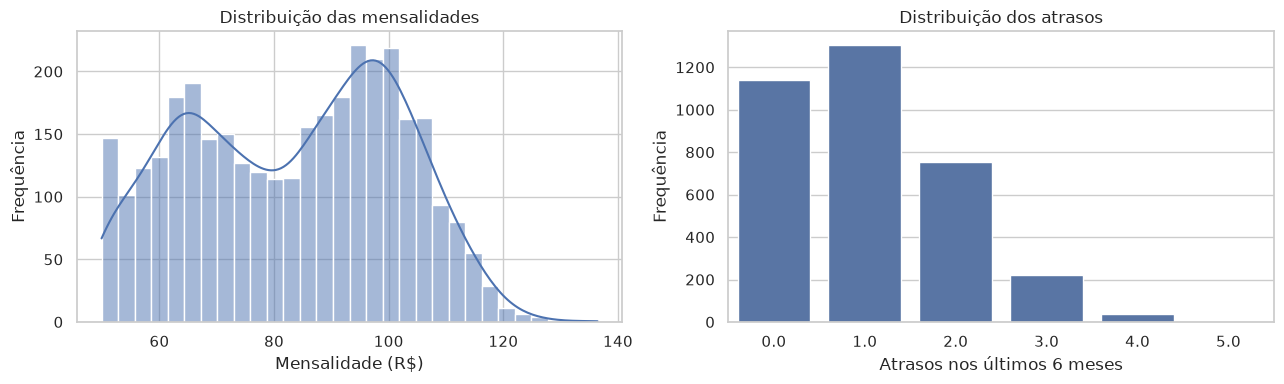

In [34]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    data=df_eda,
    x="mensalidade_rs",
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribuição das mensalidades")
axes[0].set_xlabel("Mensalidade (R$)")
axes[0].set_ylabel("Frequência")

sns.countplot(
    data=df_eda,
    x="atrasos_6m",
    order=sorted(df_eda["atrasos_6m"].dropna().unique()),
    ax=axes[1]
)

axes[1].set_title("Distribuição dos atrasos")
axes[1].set_xlabel("Atrasos nos últimos 6 meses")
axes[1].set_ylabel("Frequência")

plt.tight_layout()
plt.show()



## 15. Tempo de relacionamento dos clientes

O tempo de relacionamento representa a duração do vínculo entre o cliente e a operadora, considerando a data-base de 21/09/2026.

Como o dataset contém a data de aquisição, calculamos a variável derivada `tempo_cliente_meses`.

Essa análise permite identificar a concentração de clientes mais recentes ou antigos e compreender a distribuição do tempo de permanência na operadora.

A variável é calculada exclusivamente com informações disponíveis até a data-base.


,count,mean,std,min,25%,50%,75%,max
tempo_cliente_meses,3493.0,24.64,15.38,1.0,13.0,21.0,33.0,72.0


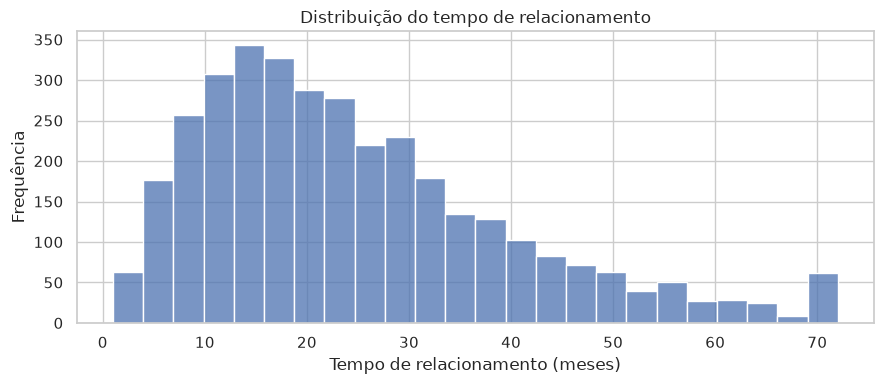

In [35]:

datas_aquisicao = aquisicao.loc[df_eda.index]

df_eda["tempo_cliente_meses"] = (
    (DATA_BASE.year - datas_aquisicao.dt.year) * 12
    + (DATA_BASE.month - datas_aquisicao.dt.month)
    - (DATA_BASE.day < datas_aquisicao.dt.day).astype(int)
)

display(
    df_eda[["tempo_cliente_meses"]]
    .describe()
    .T.round(2)
)

plt.figure(figsize=(9, 4))

sns.histplot(
    data=df_eda,
    x="tempo_cliente_meses",
    bins=24
)

plt.title("Distribuição do tempo de relacionamento")
plt.xlabel("Tempo de relacionamento (meses)")
plt.ylabel("Frequência")
plt.tight_layout()
plt.show()



## 16. Quantidade de chamados de suporte

A base armazena as datas dos chamados de suporte, podendo haver múltiplas datas em uma mesma célula.

Para analisar o comportamento dos clientes, construímos temporariamente o atributo `chamados_suporte`, correspondente à quantidade de chamados registrados nos 90 dias anteriores à data-base, incluindo o próprio dia do corte.

Serão considerados apenas chamados cronologicamente válidos, ocorridos após ou na data de aquisição do cliente e até a data-base.

O objetivo é compreender a distribuição da frequência de contato com o suporte, sem investigar ainda sua relação com o cancelamento.


,count,mean,std,min,25%,50%,75%,max
chamados_suporte,3493.0,1.71,1.43,0.0,1.0,1.0,2.0,10.0


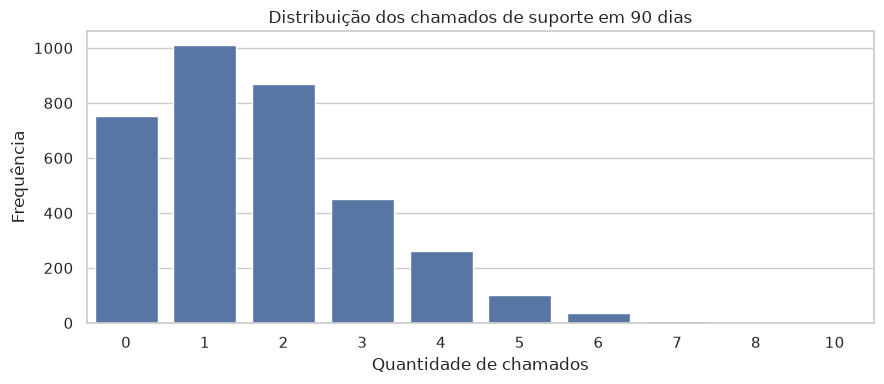

In [36]:

INICIO_CHAMADOS = DATA_BASE - pd.Timedelta(days=90)

df_eda["chamados_suporte"] = [
    sum(
        pd.notna(data)
        and INICIO_CHAMADOS <= data <= DATA_BASE
        and data >= aquisicao.loc[idx]
        for data in chamados.loc[idx]
    )
    for idx in df_eda.index
]

display(
    df_eda[["chamados_suporte"]]
    .describe()
    .T.round(2)
)

plt.figure(figsize=(9, 4))

sns.countplot(
    data=df_eda,
    x="chamados_suporte",
    order=sorted(df_eda["chamados_suporte"].unique())
)

plt.title("Distribuição dos chamados de suporte em 90 dias")
plt.xlabel("Quantidade de chamados")
plt.ylabel("Frequência")
plt.tight_layout()
plt.show()



## 17. Análise de possíveis outliers

Outliers são observações que apresentam valores significativamente diferentes da maioria dos dados.

Utilizamos um boxplot da mensalidade para visualizar a mediana, a dispersão, os quartis e possíveis valores extremos.

É importante diferenciar outliers estatísticos de valores inválidos segundo as regras de negócio. Os valores de mensalidade fora do intervalo permitido já foram desconsiderados temporariamente.

A presença de outliers não implica necessariamente que os registros devam ser removidos.


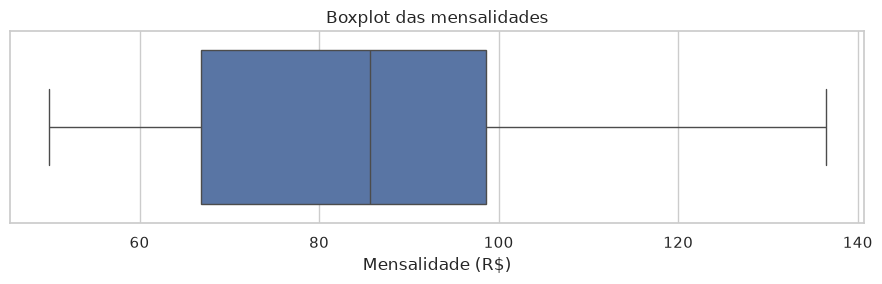

In [37]:

plt.figure(figsize=(9, 3))

sns.boxplot(
    data=df_eda,
    x="mensalidade_rs"
)

plt.title("Boxplot das mensalidades")
plt.xlabel("Mensalidade (R$)")
plt.tight_layout()
plt.show()



## 18. Distribuição dos atributos categóricos e binários

Nesta etapa, analisamos a frequência das modalidades contratuais, formas de pagamento, contratação de fibra óptica e utilização de débito automático.

Para evitar a separação artificial de categorias equivalentes, aplicamos apenas uma padronização temporária das grafias de contrato e pagamento.

Os valores ausentes permanecem identificados, sem imputação.

Essa análise permite compreender o perfil geral dos clientes presentes no conjunto de treinamento.


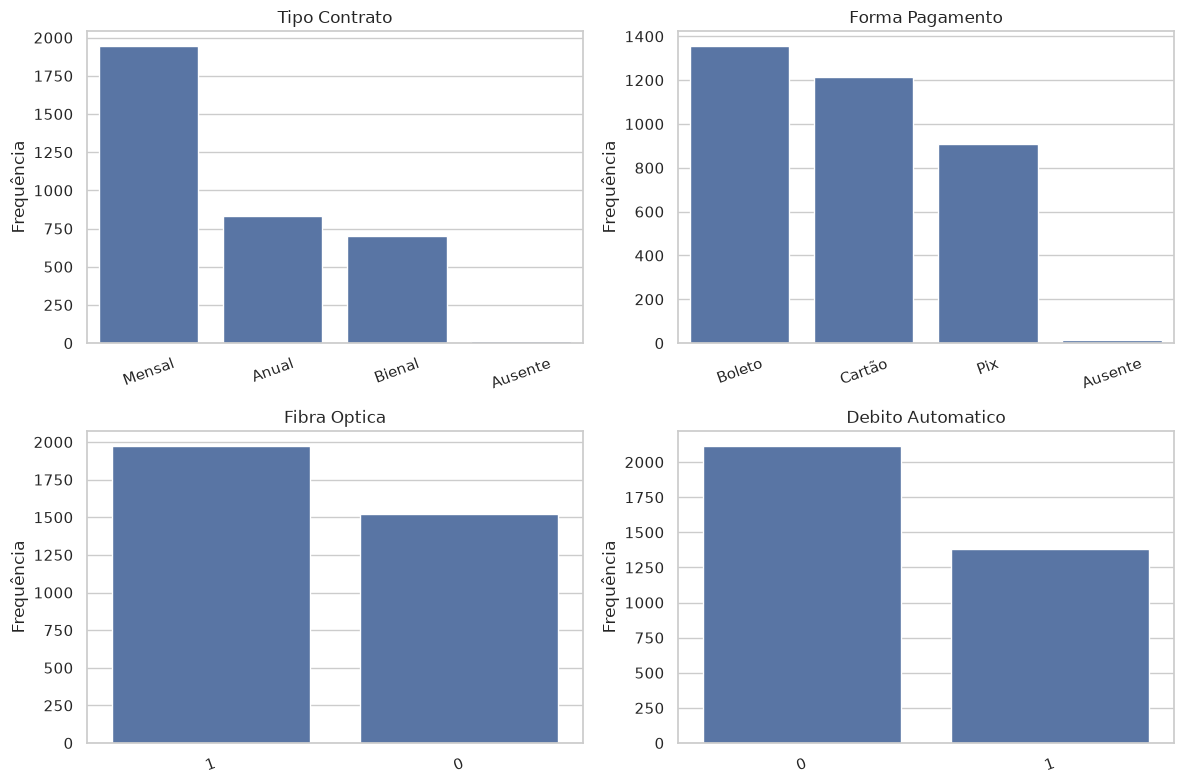

In [38]:

df_eda["tipo_contrato"] = (
    df_eda["tipo_contrato"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({
        "mensal": "Mensal",
        "anual": "Anual",
        "bienal": "Bienal"
    })
    .fillna("Ausente")
)

df_eda["forma_pagamento"] = (
    df_eda["forma_pagamento"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({
        "boleto": "Boleto",
        "cartão": "Cartão",
        "cartao": "Cartão",
        "pix": "Pix"
    })
    .fillna("Ausente")
)

categoricas = [
    "tipo_contrato",
    "forma_pagamento",
    "fibra_optica",
    "debito_automatico"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for coluna, ax in zip(categoricas, axes.flat):
    sns.countplot(
        data=df_eda,
        x=coluna,
        order=df_eda[coluna].value_counts().index,
        ax=ax
    )

    ax.set_title(coluna.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel("Frequência")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()



## 19. Conclusões da análise univariada

A análise univariada permitiu compreender as distribuições dos atributos numéricos, categóricos e binários, considerando exclusivamente o conjunto de treinamento, composto por 3.493 registros.

### Mensalidade

A mensalidade apresenta média de aproximadamente R$ 83,34 e mediana de R$ 85,65, com desvio-padrão de R$ 18,43. Os valores válidos observados variam entre R$ 49,90 e R$ 136,42.

O histograma sugere uma distribuição bimodal, com concentrações próximas de R$ 65 e R$ 95, indicando a possível existência de diferentes perfis ou faixas de contratação.

O boxplot não evidencia outliers estatísticos expressivos após a exclusão temporária dos valores inválidos.

### Atrasos nos últimos seis meses

Os clientes apresentam, em média, 1,05 atraso, com mediana de 1 e desvio-padrão de aproximadamente 0,95.

A distribuição concentra-se principalmente entre 0 e 2 atrasos, enquanto quantidades maiores são progressivamente menos frequentes. Isso indica uma distribuição assimétrica à direita.

### Tempo de relacionamento

O tempo médio de relacionamento é de 24,64 meses, enquanto a mediana é de 21 meses.

A distribuição apresenta assimetria à direita, com maior concentração de clientes entre aproximadamente 10 e 30 meses de relacionamento e menor frequência de clientes muito antigos.

### Chamados de suporte

Os clientes registraram, em média, 1,71 chamados nos últimos 90 dias, com mediana de 1 e desvio-padrão de 1,43.

A maior parte dos registros concentra-se entre 0 e 3 chamados, enquanto quantidades superiores são pouco frequentes. O máximo observado foi de 10 chamados.

### Atributos categóricos e binários

A modalidade contratual mensal é predominante, seguida pelos contratos anual e bienal.

Quanto às formas de pagamento, Boleto apresenta a maior frequência, seguido por Cartão e Pix.

A maioria dos clientes possui fibra óptica, enquanto o débito automático está desativado para a maior parte dos registros.

Após a padronização temporária das categorias, observa-se que as inconsistências de grafia podem ser resolvidas sem criar novas modalidades de contrato ou pagamento.

### Conclusão geral

Os resultados revelam diferenças importantes na distribuição das características dos clientes, especialmente em mensalidade, tempo de relacionamento, frequência de chamados e modalidade contratual.

Entretanto, a análise univariada não permite determinar quais características estão associadas ao cancelamento.

Na Parte 3, serão investigadas as relações entre essas variáveis e o churn, buscando identificar padrões que possam orientar a preparação dos dados e os futuros experimentos de aprendizagem de máquina.



# Parte 3 — Análise Bivariada e Correlações

Nesta etapa, investigamos as relações entre as características dos clientes e a ocorrência de cancelamento (*churn*), buscando identificar padrões relevantes para a compreensão do problema e a preparação da base de dados.

Diferentemente da análise univariada, que examina cada atributo individualmente, a análise bivariada permite verificar como diferentes características estão associadas à variável-alvo.

A Parte 3 contempla:

1. **Distribuição da variável-alvo:** avaliação da proporção de clientes com e sem churn e identificação de possíveis desbalanceamentos.
2. **Relação entre atributos numéricos e churn:** análise das taxas de cancelamento em função da mensalidade, tempo de relacionamento, atrasos e chamados de suporte.
3. **Relação entre atributos categóricos e churn:** comparação das taxas de cancelamento entre modalidades de contrato, formas de pagamento e indicadores binários.
4. **Análise de correlações:** investigação das associações entre atributos numéricos, incluindo possíveis redundâncias e relações com o churn.

As análises utilizam exclusivamente o conjunto de treinamento, preservando o conjunto de teste e evitando vazamento de informações (*data leakage*).

O objetivo é identificar tendências e associações que possam orientar as decisões de pré-processamento e os futuros experimentos de aprendizagem de máquina, sem estabelecer relações causais ou treinar modelos nesta etapa.



## 20. Distribuição da variável-alvo

A variável `churn` representa a ocorrência de cancelamento nos 60 dias seguintes à data-base.

- **Classe 0:** cliente sem cancelamento na janela de previsão.
- **Classe 1:** cliente que cancelou durante a janela de previsão.

Esta análise verifica a proporção de clientes em cada classe e o grau de desbalanceamento do conjunto de treinamento.

A distribuição das classes é importante porque influencia a escolha das métricas e das estratégias de treinamento dos futuros modelos supervisionados.

A existência de uma classe minoritária não implica, necessariamente, que técnicas de balanceamento precisem ser aplicadas.


,Quantidade,Percentual (%)
Sem churn,2253,64.5
Com churn,1240,35.5


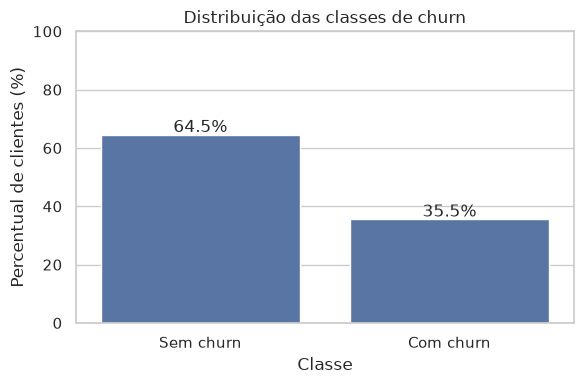

In [41]:

distribuicao_churn = (
    df_eda["churn"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

tabela_churn = pd.DataFrame({
    "Quantidade": distribuicao_churn,
    "Percentual (%)": (
        distribuicao_churn / len(df_eda) * 100
    ).round(2)
})

tabela_churn.index = ["Sem churn", "Com churn"]

display(tabela_churn)

plt.figure(figsize=(6, 4))

ax = sns.barplot(
    x=tabela_churn.index,
    y=tabela_churn["Percentual (%)"]
)

for i, valor in enumerate(tabela_churn["Percentual (%)"]):
    ax.text(i, valor + 1, f"{valor:.1f}%", ha="center")

plt.title("Distribuição das classes de churn")
plt.xlabel("Classe")
plt.ylabel("Percentual de clientes (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()



## 21. Relação entre atributos numéricos e churn

### 21.1. Mensalidade e churn

O objetivo é investigar se o valor da mensalidade está associado à ocorrência de cancelamento.

Como a mensalidade é uma variável contínua, dividimos os clientes em cinco grupos de tamanho aproximadamente semelhante, utilizando quintis calculados sobre o conjunto de treinamento.

Para cada grupo, calculamos a quantidade de clientes e a taxa de churn.

Essa abordagem permite avaliar a existência de tendências sem estabelecer faixas arbitrárias de preço.


,Clientes,Cancelamentos,Taxa_churn
faixa_mensalidade,,,
"(49.899, 64.272]",681,167,24.52
"(64.272, 77.454]",680,195,28.68
"(77.454, 91.526]",680,247,36.32
"(91.526, 100.636]",680,290,42.65
"(100.636, 136.42]",681,307,45.08


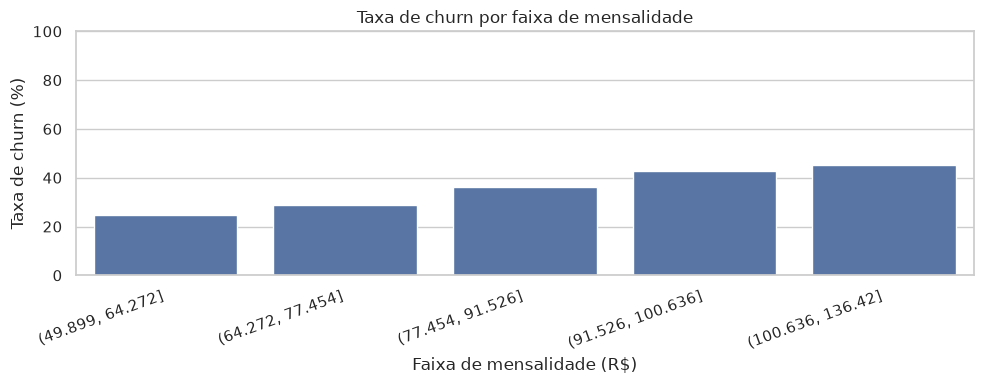

In [42]:

df_eda["faixa_mensalidade"] = pd.qcut(
    df_eda["mensalidade_rs"],
    q=5,
    duplicates="drop"
)

tabela_mensalidade = df_eda.groupby(
    "faixa_mensalidade",
    observed=True
)["churn"].agg(
    Clientes="count",
    Cancelamentos="sum",
    Taxa_churn="mean"
)

tabela_mensalidade["Taxa_churn"] *= 100

display(tabela_mensalidade.round(2))

plt.figure(figsize=(10, 4))

ax = sns.barplot(
    x=[str(x) for x in tabela_mensalidade.index],
    y=tabela_mensalidade["Taxa_churn"]
)

plt.title("Taxa de churn por faixa de mensalidade")
plt.xlabel("Faixa de mensalidade (R$)")
plt.ylabel("Taxa de churn (%)")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()



### 21.2. Tempo de relacionamento e churn

Esta análise investiga se clientes com diferentes tempos de relacionamento apresentam taxas distintas de cancelamento.

O tempo de relacionamento será agrupado em faixas de 12 meses:

- Menos de 12 meses.
- 12 a 23 meses.
- 24 a 35 meses.
- 36 a 47 meses.
- 48 meses ou mais.

Para cada faixa, calculamos a quantidade de clientes e a taxa de churn.

O objetivo é verificar se existe alguma tendência de aumento ou redução do cancelamento conforme a antiguidade do cliente.


,Clientes,Cancelamentos,Taxa_churn
faixa_tempo,,,
0–11 meses,694,365,52.59
12–23 meses,1259,498,39.56
24–35 meses,813,242,29.77
36–47 meses,401,92,22.94
48+ meses,326,43,13.19


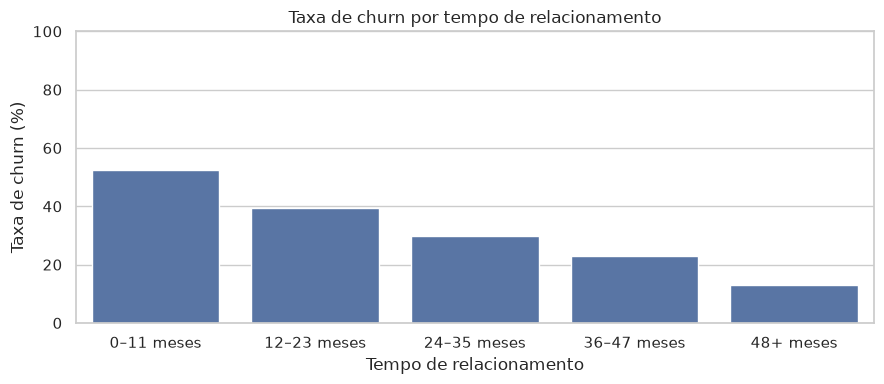

In [43]:

df_eda["faixa_tempo"] = pd.cut(
    df_eda["tempo_cliente_meses"],
    bins=[-1, 11, 23, 35, 47, np.inf],
    labels=[
        "0–11 meses",
        "12–23 meses",
        "24–35 meses",
        "36–47 meses",
        "48+ meses"
    ]
)

tabela_tempo = df_eda.groupby(
    "faixa_tempo",
    observed=True
)["churn"].agg(
    Clientes="count",
    Cancelamentos="sum",
    Taxa_churn="mean"
)

tabela_tempo["Taxa_churn"] *= 100

display(tabela_tempo.round(2))

plt.figure(figsize=(9, 4))

sns.barplot(
    x=tabela_tempo.index.astype(str),
    y=tabela_tempo["Taxa_churn"]
)

plt.title("Taxa de churn por tempo de relacionamento")
plt.xlabel("Tempo de relacionamento")
plt.ylabel("Taxa de churn (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()



### 21.3. Quantidade de atrasos e churn

O objetivo é investigar a associação entre o comportamento de pagamento dos clientes e a ocorrência de cancelamento.

A variável `atrasos_6m` representa a quantidade de atrasos nos últimos seis meses.

Como se trata de uma contagem discreta, analisamos a taxa de churn para cada quantidade de atrasos, sem necessidade de criar faixas.

Também apresentamos o número de clientes em cada grupo, pois taxas calculadas sobre poucos registros podem ser instáveis.


,Clientes,Cancelamentos,Taxa_churn
atrasos_6m,,,
0.0,1138,257,22.58
1.0,1304,470,36.04
2.0,754,357,47.35
3.0,222,119,53.60
4.0,37,28,75.68
5.0,2,0,0.00


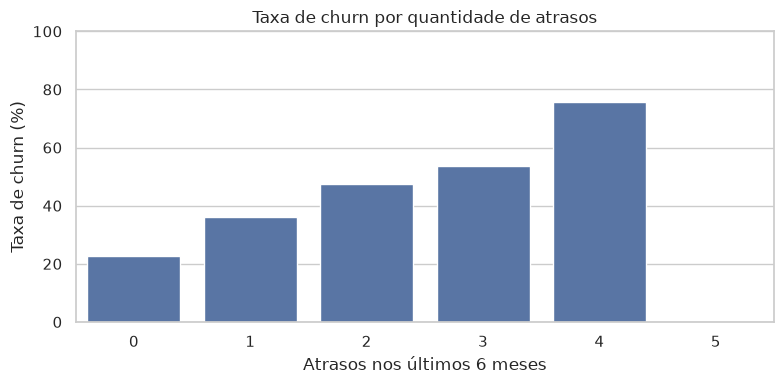

In [44]:

tabela_atrasos = df_eda.groupby(
    "atrasos_6m"
)["churn"].agg(
    Clientes="count",
    Cancelamentos="sum",
    Taxa_churn="mean"
).sort_index()

tabela_atrasos["Taxa_churn"] *= 100

display(tabela_atrasos.round(2))

plt.figure(figsize=(8, 4))

sns.barplot(
    x=tabela_atrasos.index.astype(int).astype(str),
    y=tabela_atrasos["Taxa_churn"]
)

plt.title("Taxa de churn por quantidade de atrasos")
plt.xlabel("Atrasos nos últimos 6 meses")
plt.ylabel("Taxa de churn (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()



### 21.4. Chamados de suporte e churn

Esta análise investiga a relação entre a frequência de contatos com o suporte e a ocorrência de churn.

O atributo `chamados_suporte` representa a quantidade de chamados registrados nos 90 dias anteriores à data-base.

Para evitar grupos muito pequenos, dividimos os clientes em:

- Nenhum chamado.
- Um chamado.
- Dois chamados.
- Três chamados.
- Quatro ou mais chamados.

O objetivo é verificar se clientes com maior necessidade de suporte apresentam taxas diferentes de cancelamento.


,Clientes,Cancelamentos,Taxa_churn
faixa_chamados,,,
0,754,164,21.75
1,1010,297,29.41
2,868,332,38.25
3,450,209,46.44
4 ou mais,411,238,57.91


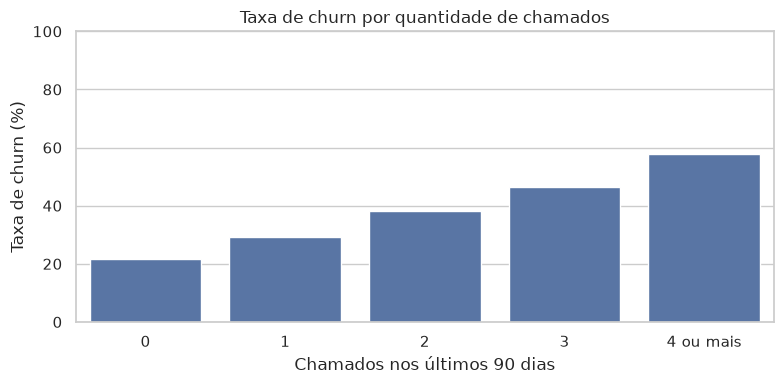

In [45]:

df_eda["faixa_chamados"] = pd.cut(
    df_eda["chamados_suporte"],
    bins=[-1, 0, 1, 2, 3, np.inf],
    labels=["0", "1", "2", "3", "4 ou mais"]
)

tabela_chamados = df_eda.groupby(
    "faixa_chamados",
    observed=True
)["churn"].agg(
    Clientes="count",
    Cancelamentos="sum",
    Taxa_churn="mean"
)

tabela_chamados["Taxa_churn"] *= 100

display(tabela_chamados.round(2))

plt.figure(figsize=(8, 4))

sns.barplot(
    x=tabela_chamados.index.astype(str),
    y=tabela_chamados["Taxa_churn"]
)

plt.title("Taxa de churn por quantidade de chamados")
plt.xlabel("Chamados nos últimos 90 dias")
plt.ylabel("Taxa de churn (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()



## 22. Relação entre atributos categóricos e churn

Esta análise investiga a associação entre as características contratuais dos clientes e a ocorrência de cancelamento.

Serão considerados:

- `tipo_contrato`: Mensal, Anual ou Bienal.
- `forma_pagamento`: Boleto, Cartão ou Pix.
- `fibra_optica`: contratação de fibra óptica.
- `debito_automatico`: utilização de débito automático.

Para cada categoria, calculamos a quantidade de clientes, a quantidade de cancelamentos e a taxa de churn.

A taxa de churn permite comparar grupos com tamanhos diferentes, sendo mais informativa do que comparar apenas o número absoluto de cancelamentos.

Os valores ausentes são mantidos como uma categoria separada para investigar se a ausência de informação também está associada ao churn.



ATRIBUTO: tipo_contrato


,Clientes,Cancelamentos,Taxa de churn (%)
tipo_contrato,,,
Mensal,1944,928,47.74
Ausente,16,6,37.50
Anual,831,199,23.95
Bienal,702,107,15.24



ATRIBUTO: forma_pagamento


,Clientes,Cancelamentos,Taxa de churn (%)
forma_pagamento,,,
Ausente,13,8,61.54
Pix,910,332,36.48
Boleto,1355,484,35.72
Cartão,1215,416,34.24



ATRIBUTO: fibra_optica


,Clientes,Cancelamentos,Taxa de churn (%)
fibra_optica,,,
1,1973,843,42.73
0,1520,397,26.12



ATRIBUTO: debito_automatico


,Clientes,Cancelamentos,Taxa de churn (%)
debito_automatico,,,
0,2114,867,41.01
1,1379,373,27.05


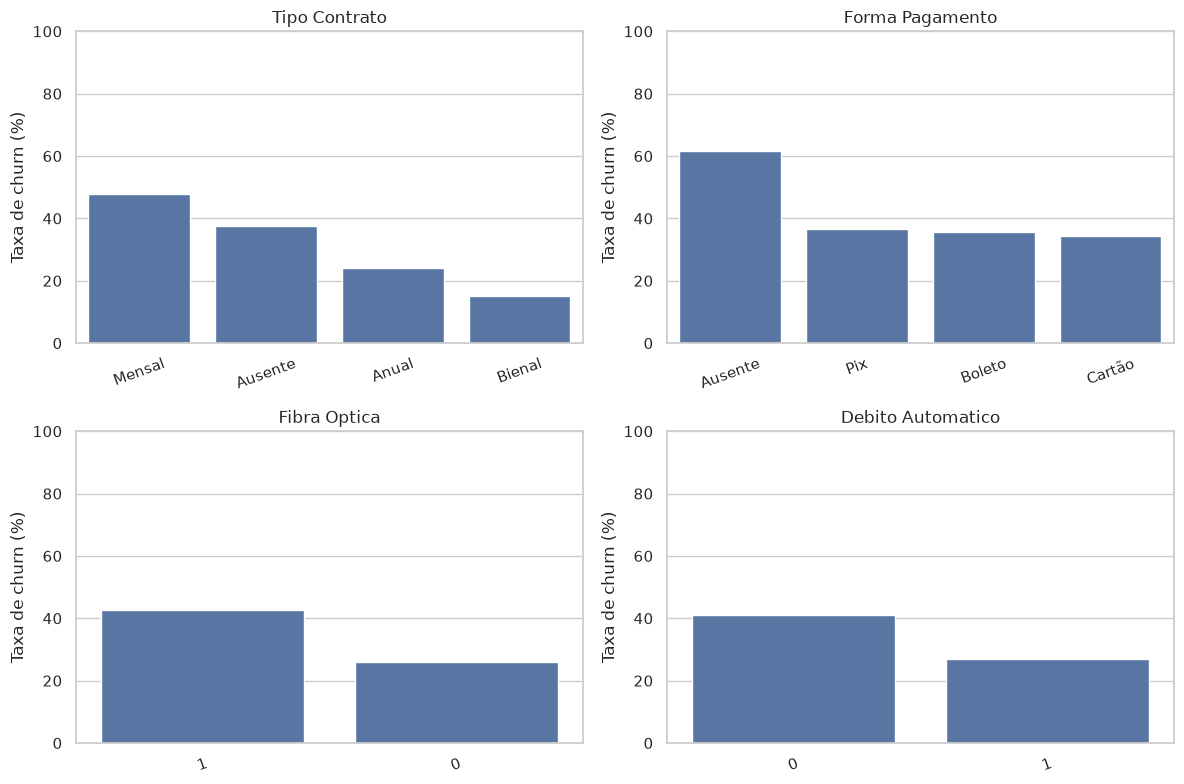

In [46]:

variaveis_categoricas = [
    "tipo_contrato",
    "forma_pagamento",
    "fibra_optica",
    "debito_automatico"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for coluna, ax in zip(variaveis_categoricas, axes.flat):

    tabela = df_eda.groupby(
        coluna, dropna=False
    )["churn"].agg(
        Clientes="count",
        Cancelamentos="sum",
        Taxa_churn="mean"
    )

    tabela["Taxa_churn"] *= 100
    tabela = tabela.sort_values("Taxa_churn", ascending=False)

    print(f"\nATRIBUTO: {coluna}")
    display(
        tabela.rename(
            columns={"Taxa_churn": "Taxa de churn (%)"}
        ).round(2)
    )

    sns.barplot(
        x=tabela.index.astype(str),
        y=tabela["Taxa_churn"],
        ax=ax
    )

    ax.set_title(coluna.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel("Taxa de churn (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()



## 23. Correlações entre atributos numéricos

O objetivo é investigar associações entre as variáveis numéricas e identificar possíveis redundâncias.

Utilizamos o coeficiente de Spearman, que mede a intensidade e a direção de associações monotônicas.

O coeficiente varia entre -1 e 1:

- **Próximo de 1:** associação positiva forte.
- **Próximo de -1:** associação negativa forte.
- **Próximo de 0:** ausência de associação monotônica expressiva.

Incluímos a variável `churn` para examinar suas associações com os atributos numéricos.

Entretanto, correlação não implica causalidade. Além disso, valores próximos de zero não descartam relações não monotônicas.

As variáveis categóricas nominais não serão incluídas na matriz, pois atribuir números arbitrários às categorias pode produzir correlações sem significado.


,mensalidade_rs,tempo_cliente_meses,atrasos_6m,chamados_suporte,churn
mensalidade_rs,1.000,0.025,0.012,0.193,0.167
tempo_cliente_meses,0.025,1.000,0.032,-0.206,-0.246
atrasos_6m,0.012,0.032,1.000,-0.004,0.227
chamados_suporte,0.193,-0.206,-0.004,1.000,0.232
churn,0.167,-0.246,0.227,0.232,1.000


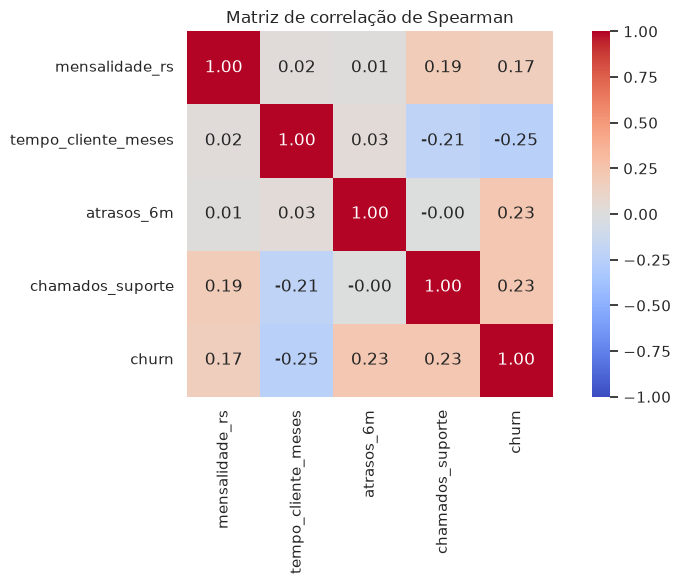

In [47]:

colunas_correlacao = [
    "mensalidade_rs",
    "tempo_cliente_meses",
    "atrasos_6m",
    "chamados_suporte",
    "churn"
]

correlacoes = df_eda[
    colunas_correlacao
].corr(method="spearman")

display(correlacoes.round(3))

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlacoes,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Matriz de correlação de Spearman")
plt.tight_layout()
plt.show()


## 24. Conclusões da análise bivariada e de correlações

A análise bivariada permitiu investigar as associações entre as características dos clientes e a ocorrência de churn, utilizando os 3.493 registros do conjunto de treinamento.

### 24.1. Distribuição das classes

A base apresenta **64,50% de clientes sem churn (2.253)** e **35,50% com churn (1.240)**.

Observa-se um desbalanceamento moderado, com predominância da classe de permanência. Essa distribuição deve ser considerada nos futuros experimentos supervisionados, especialmente na escolha de métricas como precisão, recall e F1-score.

### 24.2. Relação entre atributos numéricos e churn

As análises revelaram tendências relevantes:

- **Mensalidade:** a taxa de churn apresenta tendência crescente conforme aumenta o valor da mensalidade, passando de aproximadamente 24% na menor faixa para 45% na maior faixa.
- **Tempo de relacionamento:** apresenta uma associação inversa com o churn. Clientes com menos de 12 meses possuem taxa de cancelamento de **52,59%**, enquanto aqueles com 48 meses ou mais apresentam **13,19%**.
- **Atrasos:** a taxa de churn cresce de **22,58%**, entre clientes sem atrasos, para **75,68%**, entre aqueles com quatro atrasos. A categoria de cinco atrasos possui apenas dois registros, não permitindo uma conclusão confiável.
- **Chamados de suporte:** observa-se aumento progressivo da taxa de churn conforme cresce o número de chamados, atingindo **57,91%** entre clientes com quatro ou mais chamados nos últimos 90 dias.

Esses resultados sugerem que menor tempo de relacionamento, maior frequência de chamados, atrasos recorrentes e mensalidades elevadas estão associados a maiores taxas de cancelamento.

### 24.3. Relação entre atributos categóricos e churn

As características contratuais também apresentam diferenças relevantes:

- **Tipo de contrato:** clientes com contrato mensal apresentam a maior taxa de churn, aproximadamente 47%, enquanto contratos bienais apresentam a menor, próxima de 15%.
- **Forma de pagamento:** Boleto, Cartão e Pix apresentam taxas relativamente próximas, enquanto a categoria de pagamento ausente apresenta taxa mais elevada. Essa última deve ser interpretada com cautela devido à pequena quantidade de registros.
- **Fibra óptica:** clientes com fibra apresentam taxa de churn de aproximadamente 43%, superior aos 26% observados entre clientes sem fibra.
- **Débito automático:** clientes que utilizam débito automático apresentam taxa próxima de 27%, enquanto aqueles que não utilizam apresentam aproximadamente 41%.

Essas diferenças indicam associações entre o perfil contratual e a ocorrência de churn, mas não permitem estabelecer relações causais.

### 24.4. Análise de correlações

A matriz de Spearman identificou as seguintes associações com a variável-alvo:

| Atributo | Correlação com churn |
|---|---:|
| Tempo de relacionamento | -0,246 |
| Chamados de suporte | +0,232 |
| Atrasos nos últimos 6 meses | +0,227 |
| Mensalidade | +0,167 |

O tempo de relacionamento apresentou a associação monotônica negativa mais expressiva, enquanto chamados e atrasos apresentaram associações positivas.

Embora os coeficientes sejam relativamente baixos em magnitude, os gráficos por faixas revelaram tendências relevantes. Isso demonstra a importância de complementar a análise de correlação com outras visualizações.

Entre os próprios atributos numéricos, não foram observadas correlações muito elevadas, não havendo evidências de redundância linear ou monotônica forte apenas com base nessa matriz.

### 24.5. Conclusão geral da Parte 3

A análise identificou padrões consistentes de associação entre churn e características financeiras, comportamentais e contratuais dos clientes.

Os resultados mais relevantes foram a maior taxa de cancelamento entre clientes com pouco tempo de relacionamento, contratos mensais, maior frequência de chamados e maior quantidade de atrasos.

Essas descobertas justificam a preservação e a construção adequada desses atributos na base analítica, pois podem conter informações úteis para os próximos miniprojetos.

Entretanto, as relações identificadas são exploratórias e não garantem capacidade preditiva, nem demonstram causalidade.

A próxima etapa será o **pré-processamento**, contemplando a resolução das inconsistências identificadas na auditoria, o tratamento dos valores ausentes, a consolidação dos atributos derivados e a preparação de uma base consistente e reproduzível para os futuros experimentos de aprendizagem de máquina.